# Advance Bank Term Deposit

## Introduction
This notebook provides a detailed analysis of customer behavior and insights into factors influencing term deposit subscription.

## Load Dataset

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Load data
df = pd.read_csv('data.csv')
df

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41183,73,retired,married,professional.course,no,yes,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes
41184,46,blue-collar,married,professional.course,no,no,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41185,56,retired,married,university.degree,no,yes,no,cellular,nov,fri,...,2,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41186,44,technician,married,professional.course,no,no,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes


## Customer Demographics Analysis

C:\Users\Asus\AppData\Local\Temp\ipykernel_13404\2918362006.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Age_Group',order=['Young','Middle Age','Old'],palette='Set2',width=0.5)


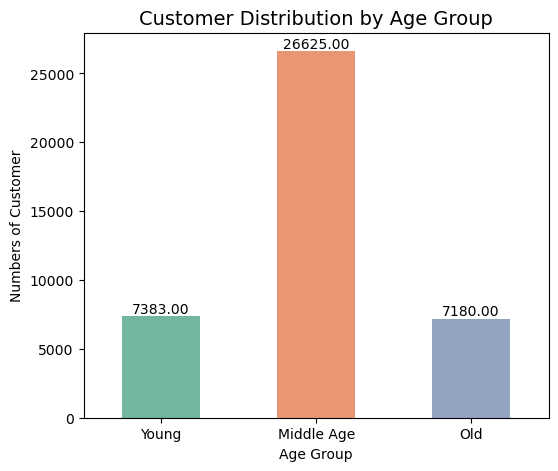

In [3]:
# Age distribution
def categorize_age(age):
    if age <= 30:
        return 'Young'
    elif age <=50:
        return 'Middle Age'
    else:
        return 'Old'

# Apply function
df['Age_Group'] = df['age'].apply(categorize_age)

# Count plot using seaborn
plt.figure(figsize=(6,5),)
sns.countplot(data=df, x='Age_Group',order=['Young','Middle Age','Old'],palette='Set2',width=0.5)

# Visualization
plt.title('Customer Distribution by Age Group',fontsize=14)
plt.xlabel('Age Group')
plt.ylabel('Numbers of Customer')

# Show value on top of Bars
for p in plt.gca().patches:
    plt.gca().annotate(
        f'{p.get_height():.2f}',
        (p.get_x() + p.get_width()/2.,p.get_height()),
        ha='center', va='bottom'
    )

plt.show()

C:\Users\Asus\AppData\Local\Temp\ipykernel_18184\309703355.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=job_counts,y='job',x='count',palette='coolwarm',width=0.5)


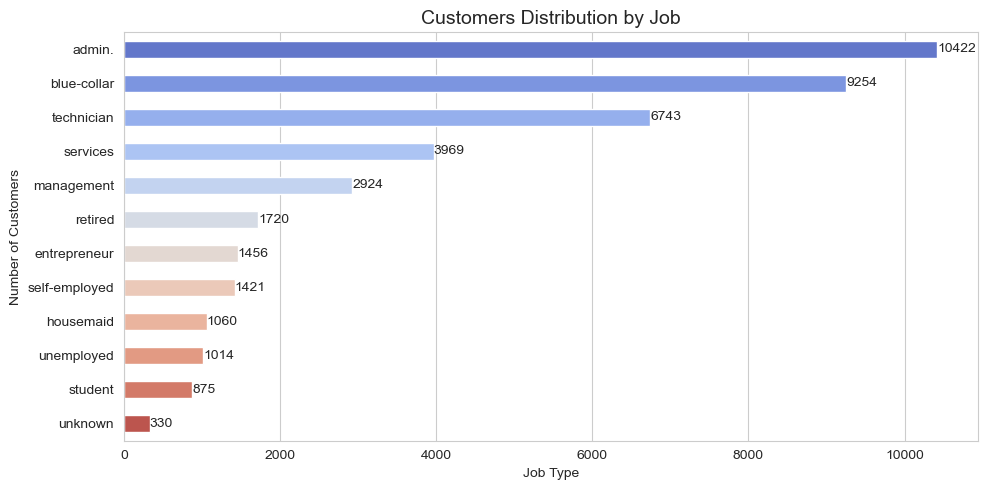

In [53]:
# Job distribution
df['job'] = df['job'].fillna('Unknown') # For missing value

# Count job categories
job_counts = df['job'].value_counts().reset_index()
job_counts.columns = ['job','count']

# Sort values (optional but recommended)
job_counts = job_counts.sort_values(by='count',ascending=False)

# Visualization
sns.set_style("whitegrid")
plt.figure(figsize=(10,5))
sns.barplot(data=job_counts,y='job',x='count',palette='coolwarm',width=0.5)
plt.title('Customers Distribution by Job',fontsize=14)
plt.xlabel('Job Type')
plt.ylabel('Number of Customers')
#plt.xticks(rotation=45) # Rotate x label for readability
for i,v in enumerate(job_counts['count']):
    plt.text(v,i, str(v),va='center')

plt.tight_layout()
plt.show()

## Balance & Deposit Trends

In [4]:
df

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y,Age_Group
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,Old
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,Old
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,Middle Age
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,Middle Age
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,Old
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41183,73,retired,married,professional.course,no,yes,no,cellular,nov,fri,...,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes,Old
41184,46,blue-collar,married,professional.course,no,no,no,cellular,nov,fri,...,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no,Middle Age
41185,56,retired,married,university.degree,no,yes,no,cellular,nov,fri,...,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no,Old
41186,44,technician,married,professional.course,no,no,no,cellular,nov,fri,...,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes,Middle Age


In [5]:
# Add Balance column
df['balance'] = 0

# Loop through each row
for i in range(len(df)):
    balance = np.random.randint(2000,10000)
    # Loan Condition
    if df.loc[i,'loan'] == 'yes':
        balance = balance-2000
    else:
        balance = balance +500
        
    # Housing Loan
    if df.loc[i,'housing'] == 'yes':
        balance = balance - 3000
    else:
        balance = balance + 500
        
    # Education condition
    if df.loc[i,'education'] == 'territary':
        balance = balance + 3000
    elif df.loc[i,'education'] == 'secondary':
        balance = balance + 1000
    else:
        balance = balance + 500
        
    # Job condition
    if df.loc[i,'job'] in ['management','entrepreneur','self-employed']:
        balance = balance + 4000
    else:
        balance = balance + 1000
        
    # Ensure balance is not negative
    if balance < 0:
        balance = 0
        
    # Assign back to dataframe
    df.loc[i,'balance'] = balance

df

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y,Age_Group,balance
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,Old,7587
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,Old,12337
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,Middle Age,7032
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,Middle Age,11740
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,Old,6276
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41183,73,retired,married,professional.course,no,yes,no,cellular,nov,fri,...,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes,Old,7253
41184,46,blue-collar,married,professional.course,no,no,no,cellular,nov,fri,...,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no,Middle Age,7959
41185,56,retired,married,university.degree,no,yes,no,cellular,nov,fri,...,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no,Old,8652
41186,44,technician,married,professional.course,no,no,no,cellular,nov,fri,...,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes,Middle Age,9535


C:\Users\Asus\AppData\Local\Temp\ipykernel_13404\937241278.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=avg_balance,y='Subscription',x='Avg_Balance',palette='coolwarm',width=0.5)


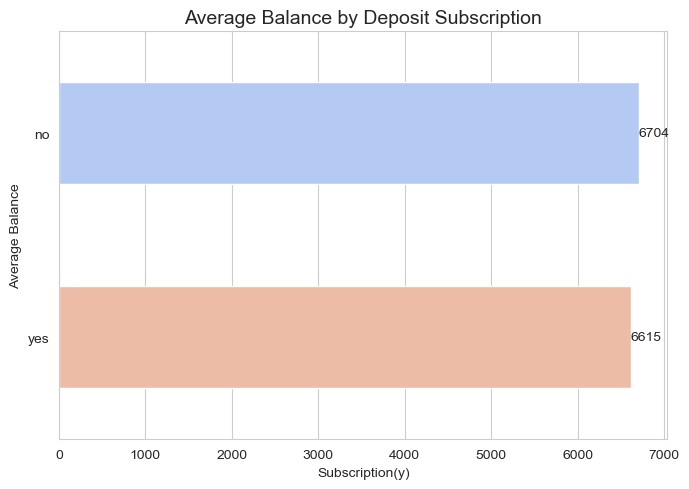

In [6]:
# Average balance by deposit subscription
df['balance'] = pd.to_numeric(df['balance'],errors='coerce')
df['y'] = df['y'].fillna('Unknown') # For missing value

# Count job categories
avg_balance = df.groupby('y')['balance'].mean().reset_index()

avg_balance.columns = ['Subscription','Avg_Balance']

# Visualization
sns.set_style("whitegrid")
plt.figure(figsize=(7,5))
sns.barplot(data=avg_balance,y='Subscription',x='Avg_Balance',palette='coolwarm',width=0.5)
plt.title('Average Balance by Deposit Subscription',fontsize=14)
plt.xlabel('Subscription(y)')
plt.ylabel('Average Balance')
for i,v in enumerate(avg_balance['Avg_Balance']):
    plt.text(v,i,f'{v:.0f}',va='center')

plt.tight_layout()
plt.show()

In [7]:
df

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y,Age_Group,balance
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,Old,7587
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,Old,12337
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,Middle Age,7032
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,Middle Age,11740
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,Old,6276
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41183,73,retired,married,professional.course,no,yes,no,cellular,nov,fri,...,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes,Old,7253
41184,46,blue-collar,married,professional.course,no,no,no,cellular,nov,fri,...,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no,Middle Age,7959
41185,56,retired,married,university.degree,no,yes,no,cellular,nov,fri,...,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no,Old,8652
41186,44,technician,married,professional.course,no,no,no,cellular,nov,fri,...,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes,Middle Age,9535


## Campaign Effectiveness

  Contact_Method  Conversion_Rate  Total_Customers  Conversion_Rate(%)
1      telephone         0.052313            15044            5.231321
0       cellular         0.147376            26144           14.737607


C:\Users\Asus\AppData\Local\Temp\ipykernel_13404\2354450255.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=contact_summary,x='Contact_Method',y='Conversion_Rate(%)',palette='Accent')


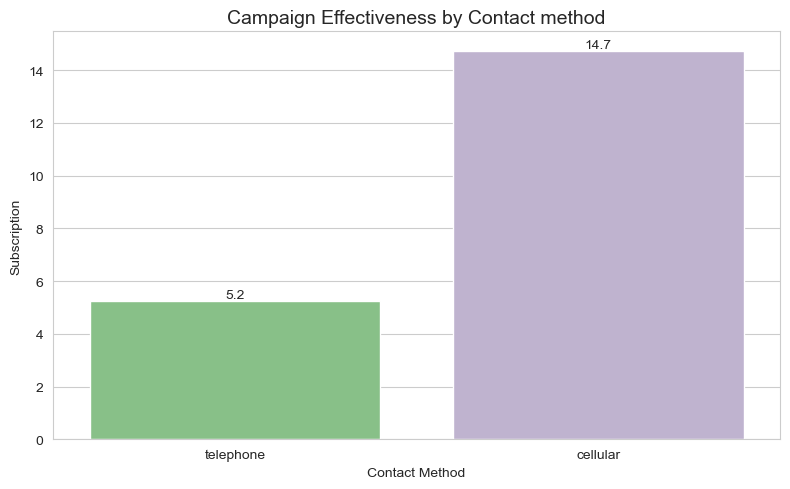

In [8]:
# Contact method analysis
df['contact'] = df['contact'].fillna('Unknown')
df['y'] = df['y'].fillna('Unknown')

# Convert target to numeric
df['y_numeric'] = df['y'].map({'yes':1,'no':0})

# Summary analysis (conversion rate)
contact_summary = df.groupby('contact')['y_numeric'].agg(['mean','count']).reset_index()
contact_summary.columns = ['Contact_Method','Conversion_Rate','Total_Customers']

# Convert Percentage
contact_summary['Conversion_Rate(%)'] = contact_summary['Conversion_Rate']*100

# Sort for Visualization
contact_summary = contact_summary.sort_values(by='Conversion_Rate(%)',ascending=True)
print(contact_summary)

# Visualization (Bar Plot)
sns.set_style('whitegrid')
plt.figure(figsize=(8,5))

sns.barplot(data=contact_summary,x='Contact_Method',y='Conversion_Rate(%)',palette='Accent')
plt.title('Campaign Effectiveness by Contact method',fontsize=14)
plt.xlabel('Contact Method')
plt.ylabel('Subscription')

# Add value labels
for i,v in enumerate(contact_summary['Conversion_Rate(%)']):
    plt.text(i, v, f'{v:.1f}',ha='center', va='bottom')

plt.tight_layout()
plt.show()

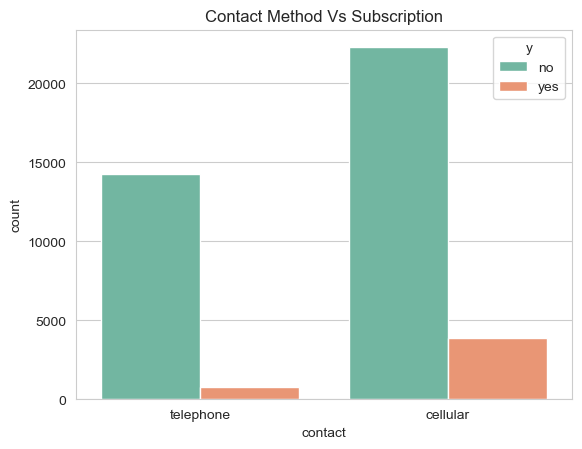

In [9]:
# Number of contacts vs deposit subscription
sns.countplot(data=df, x='contact', hue='y', palette='Set2')
plt.title('Contact Method Vs Subscription')
plt.show()

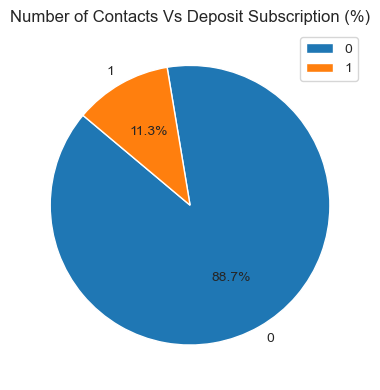

In [39]:
subscription_counts = df['y'].value_counts()
plt.figure(figsize=(4,4))
plt.pie(subscription_counts,labels=subscription_counts.index,autopct='%1.1f%%',startangle=140)
plt.legend()
plt.title('Number of Contacts Vs Deposit Subscription (%)')
plt.tight_layout()
plt.show()

## Correlation Heatmap

In [10]:
df

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y,Age_Group,balance,y_numeric
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,Old,7587,0
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,Old,12337,0
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,Middle Age,7032,0
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,Middle Age,11740,0
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,Old,6276,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41183,73,retired,married,professional.course,no,yes,no,cellular,nov,fri,...,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes,Old,7253,1
41184,46,blue-collar,married,professional.course,no,no,no,cellular,nov,fri,...,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no,Middle Age,7959,0
41185,56,retired,married,university.degree,no,yes,no,cellular,nov,fri,...,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no,Old,8652,0
41186,44,technician,married,professional.course,no,no,no,cellular,nov,fri,...,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes,Middle Age,9535,1


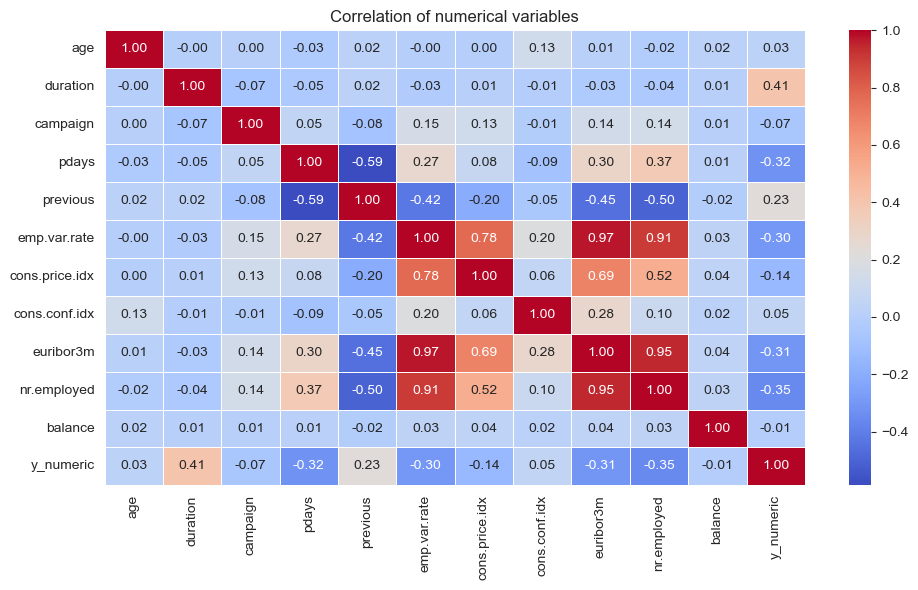

In [11]:
# Correlation of numerical variables
num_df = df.select_dtypes(include = ['int64','float64'])

# Compute correlation matrix
corr_matrix = num_df.corr()
#print(corr_matrix)

# Plot Heatmap
plt.figure(figsize=(10,6))
sns.heatmap(corr_matrix,annot=True,cmap='coolwarm',fmt='.2f',linewidths=0.5)
plt.title('Correlation of numerical variables')
plt.tight_layout()
plt.show()

## Predictive Modeling (Logistic Regression)

In [15]:


# Encode categorical variables

# Predictions

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [30]:
# Encode Variables
le = LabelEncoder()
for col in df.select_dtypes(include='object').columns:
    df[col] = le.fit_transform(df[col])

# Define Features & Target
X = df.drop('y', axis=1)  # Features
y = df['y']               # Target (Subscription)

# Train Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train Model
model = LogisticRegression(solver='liblinear',max_iter=1000,C=1.0)
#model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

# Predictions
y_pred = model.predict(X_test)

print("Accuracy: ",accuracy_score(y_test, y_pred))
print("\nConfusion Matrix:\n",confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n",classification_report(y_test, y_pred))

Accuracy:  0.9996358339402768

Confusion Matrix:
 [[7300    3]
 [   0  935]]

Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00      7303
           1       1.00      1.00      1.00       935

    accuracy                           1.00      8238
   macro avg       1.00      1.00      1.00      8238
weighted avg       1.00      1.00      1.00      8238



In [35]:
# Feature importance
importance = pd.DataFrame({
    'Feature':X.columns,
    'Importance':model.coef_[0]
})

# Sort by importance
importance = importance.sort_values(by='Importance',ascending=False)
print(importance.head())

           Feature  Importance
22       y_numeric    6.326982
16  cons.price.idx    0.225724
14        poutcome    0.166354
18       euribor3m    0.118008
20       Age_Group    0.075878


C:\Users\Asus\AppData\Local\Temp\ipykernel_13404\489261201.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_features,x='Importance',y='Feature',palette='Set2')


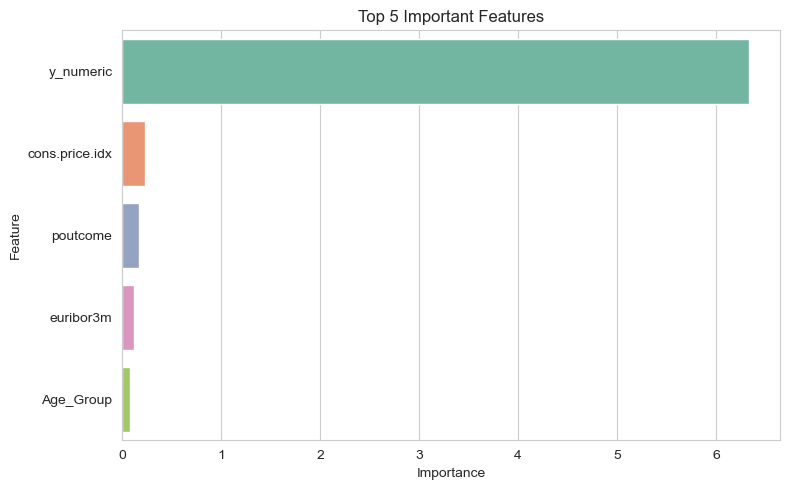

In [38]:
# Visualization Of Top 5 Features
top_features = importance.head()
plt.figure(figsize=(8,5))
sns.barplot(data=top_features,x='Importance',y='Feature',palette='Set2')
plt.title('Top 5 Important Features')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

## Key Takeaways
- Certain age groups and job categories are more likely to subscribe.
- Higher balances correlate with higher subscription rates.
- Cellular contact is more effective than telephone.
- Campaign duration and number of contacts influence outcomes.
- Logistic regression shows which features are strongest predictors.